# Develop and evaluate a model that predicts term-deposit subscription to support the selection of customers for a marketing campaign.

## TASK 1: Explore and write a short report on the data and carryout necessary data preparation, with justification. Establish a majority-class baseline.

### Imports

In [1]:
# Standard library
import os
import warnings
warnings.filterwarnings("ignore")

# Data
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("pandas:", pd.__version__)
print("numpy :", np.__version__)

pandas: 2.3.3
numpy : 2.3.5


### Loading Data

In [2]:
DATA_PATH = "bank-additional-full.csv"

df = pd.read_csv(DATA_PATH, sep=";")   
print("Shape:", df.shape)
df.head()



Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**The dataset was loaded from the UCI Bank Marketing dataset (bank-additional-full.csv), semicolon-delimited, containing 41,188 records and 21 columns: 20 predictor variables and one target y**

### Checking the Structure of the Dataset

In [3]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
# Splitting columns in to Numeric vs Categorical for Tracking
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print("Numeric columns ({}):".format(len(num_cols)))
print(num_cols)
print("\nCategorical columns ({}):".format(len(cat_cols)))
print(cat_cols)

Numeric columns (10):
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical columns (11):
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


### Target Variable Distribution

In [5]:
# Target distribution
print(df["y"].value_counts())
print("\nProportions:")
print(df["y"].value_counts(normalize=True).round(4))

y
no     36548
yes     4640
Name: count, dtype: int64

Proportions:
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


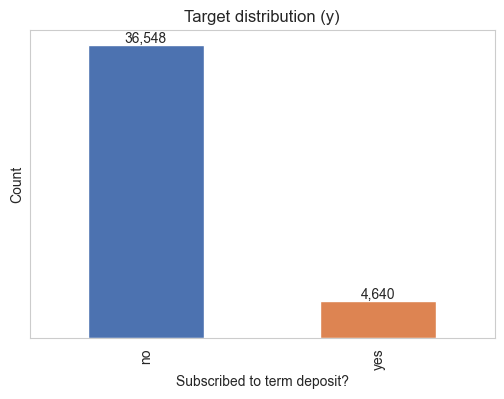

In [6]:
# Plotting
plt.figure(figsize=(6, 4))

ax = df["y"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"])

ax.set_title("Target distribution (y)")
ax.set_xlabel("Subscribed to term deposit?")
ax.set_ylabel("Count")

# Removing gridlines and y-axis tick labels
ax.grid(False)
ax.set_yticks([])

# Adding count labels above bars
for i, v in enumerate(df["y"].value_counts().values):
    ax.text(i, v + 300, f"{v:,}", ha="center")

# Save chart
plt.savefig("target_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

### Missing Values

In [7]:
# Checking for unknown values
unknown_counts = {}
for c in cat_cols:
    n = (df[c] == "unknown").sum()
    if n > 0:
        unknown_counts[c] = (n, round(100 * n / len(df), 2))

unknown_df = pd.DataFrame(unknown_counts, index=["count", "pct"]).T.sort_values("pct", ascending=False)
print(unknown_df)

            count    pct
default    8597.0  20.87
education  1731.0   4.20
housing     990.0   2.40
loan        990.0   2.40
job         330.0   0.80
marital      80.0   0.19


**Several categorical features encode missingness as the literal string 'unknown'. The highest is default (~21%), followed by education, housing, loan, job, and marital (all under ~5%). This 'unknown' will be retained as its own category. This is justified because 'unknown' may itself be informative, and tree-based models handle it natively once encoded.**

### Duplicates

In [8]:
# Counting duplicates
n_dupes = df.duplicated().sum()
print("Full-row duplicates:", n_dupes)
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(25)


Full-row duplicates: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


In [9]:
# Cleaning the duplicates
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Before:", len(df), " After:", len(df_clean), " Removed:", len(df) - len(df_clean))

Before: 41188  After: 41176  Removed: 12


**Twelve fully duplicated rows were identified and removed. This is because identical values across 21 variable would otherwise bias the model slightly and inflate the 'yes' class. The cleaned dataset has 41,176 records.**

### Exploring Numeric Variables

In [10]:
# Distributions
df_clean[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41176.0,258.32,259.31,0.00,102.00,180.00,319.00,4918.00
campaign,41176.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41176.0,962.46,186.94,0.00,999.00,999.00,999.00,999.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


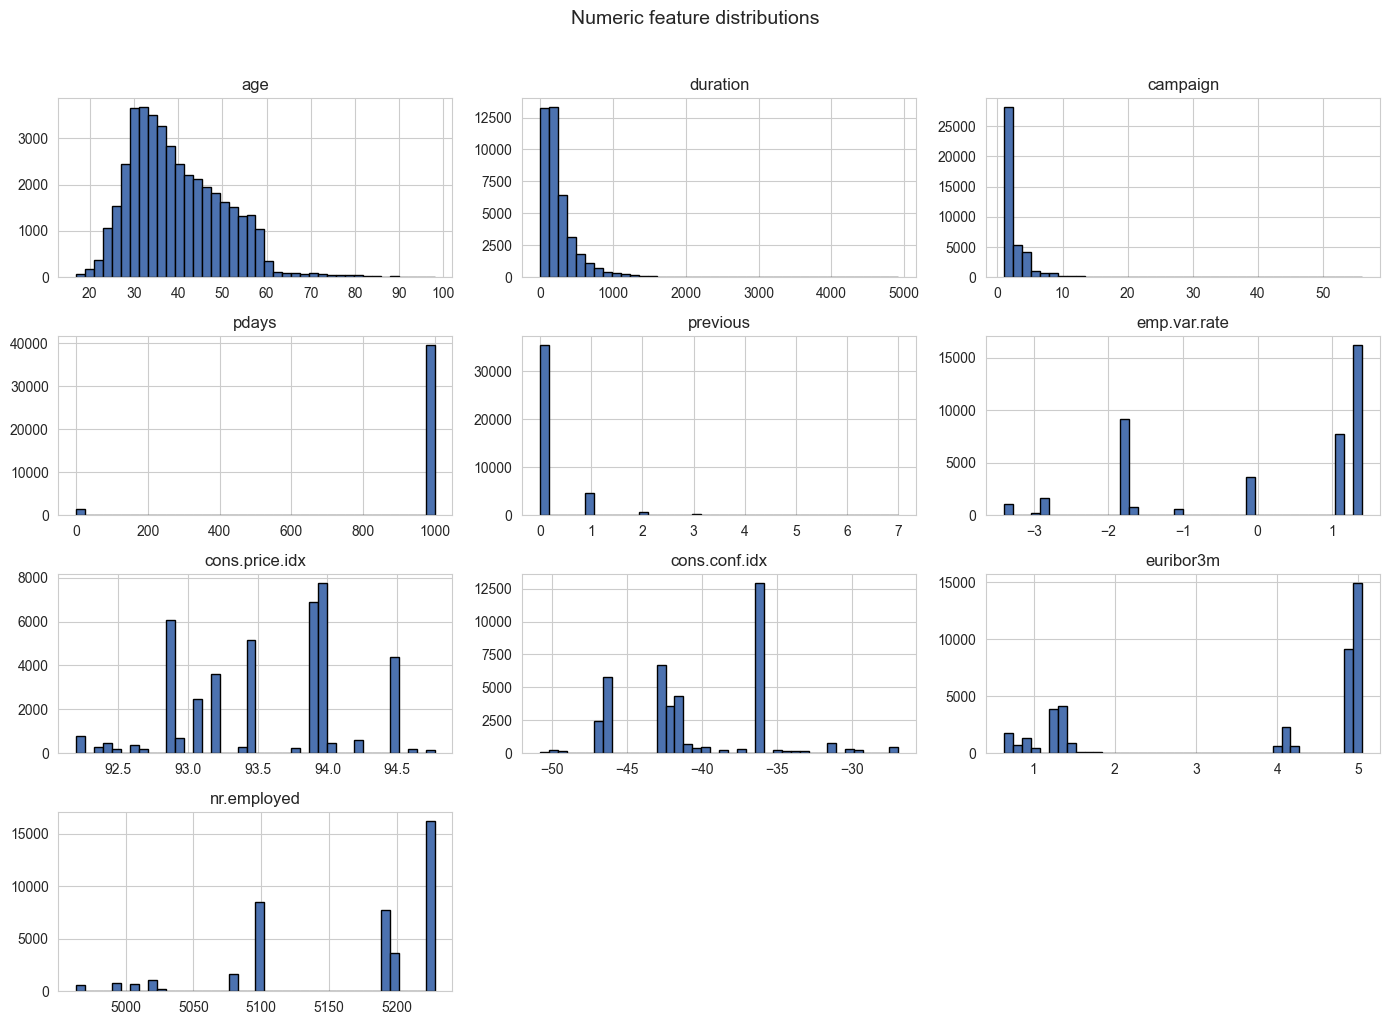

In [11]:
# Histograms
df_clean[num_cols].hist(bins=40, figsize=(14, 10), color="#4C72B0", edgecolor="black")
plt.suptitle("Numeric feature distributions", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

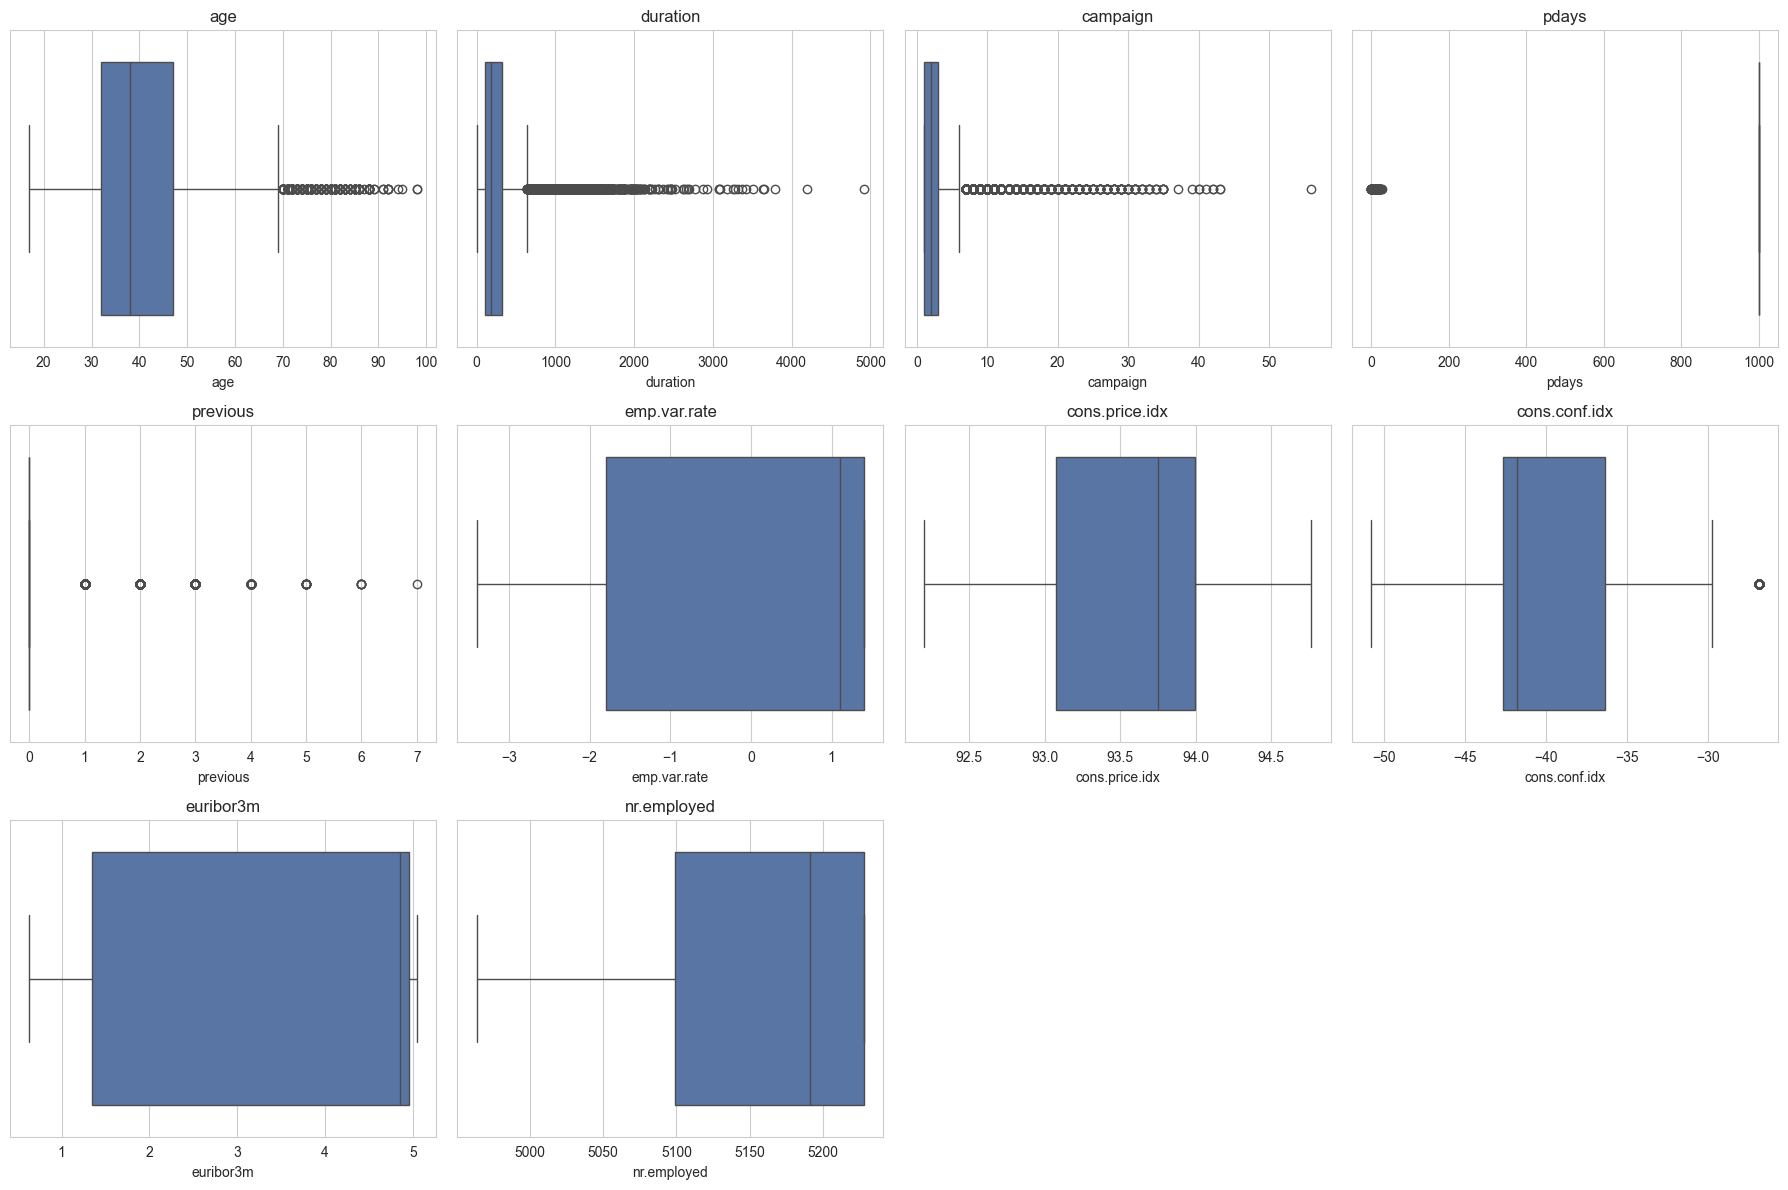

In [12]:
# Boxplots to spot outliers
n_cols = len(num_cols)
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.ravel() # Flatten the 2D array of axes to 1D

for i, col in enumerate(num_cols):
    sns.boxplot(data=df_clean, x=col, ax=axes[i], color="#4C72B0")
    axes[i].set_title(col)

# Hide any empty subplots (since we have 10 features and 12 slots)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

**Boxplot inspection reveals significant right-skewness and extreme values in several features. duration (which will be excluded), campaign (up to ~56 contacts), and previous exhibit long outlier tails. These represent real client behavior (e.g., heavily re-contacted clients) rather than data entry errors, so they are not deleted. However, for distance-based and linear models (like Logistic Regression), this skewness may degrade performance. Tree-based models (like XGBoost/Random Forest) are invariant to these monotonic transformations. Furthermore, the boxplots confirm the pdays 999 sentinel value, appearing as a dense cluster at the far right, it will therefore be recoded. Finally, the macro-economic indicators show wide interquartile ranges rather than outlier tails, confirming they vary by time period rather than by individual client.**

### Exploring Categorical Features

In [13]:
# Cardinality and value counts
for c in cat_cols:
    print(f"--- {c} ({df_clean[c].nunique()} levels) ---")
    print(df_clean[c].value_counts().head(10))
    print()

--- job (12 levels) ---
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
Name: count, dtype: int64

--- marital (4 levels) ---
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

--- education (8 levels) ---
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

--- default (3 levels) ---
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64

--- housing (3 levels) ---
housing
yes        21571
no         18615
unknown      990
Name: count, dtype: int64

--- loan (3 levels) ---
loan
no         33938
yes        

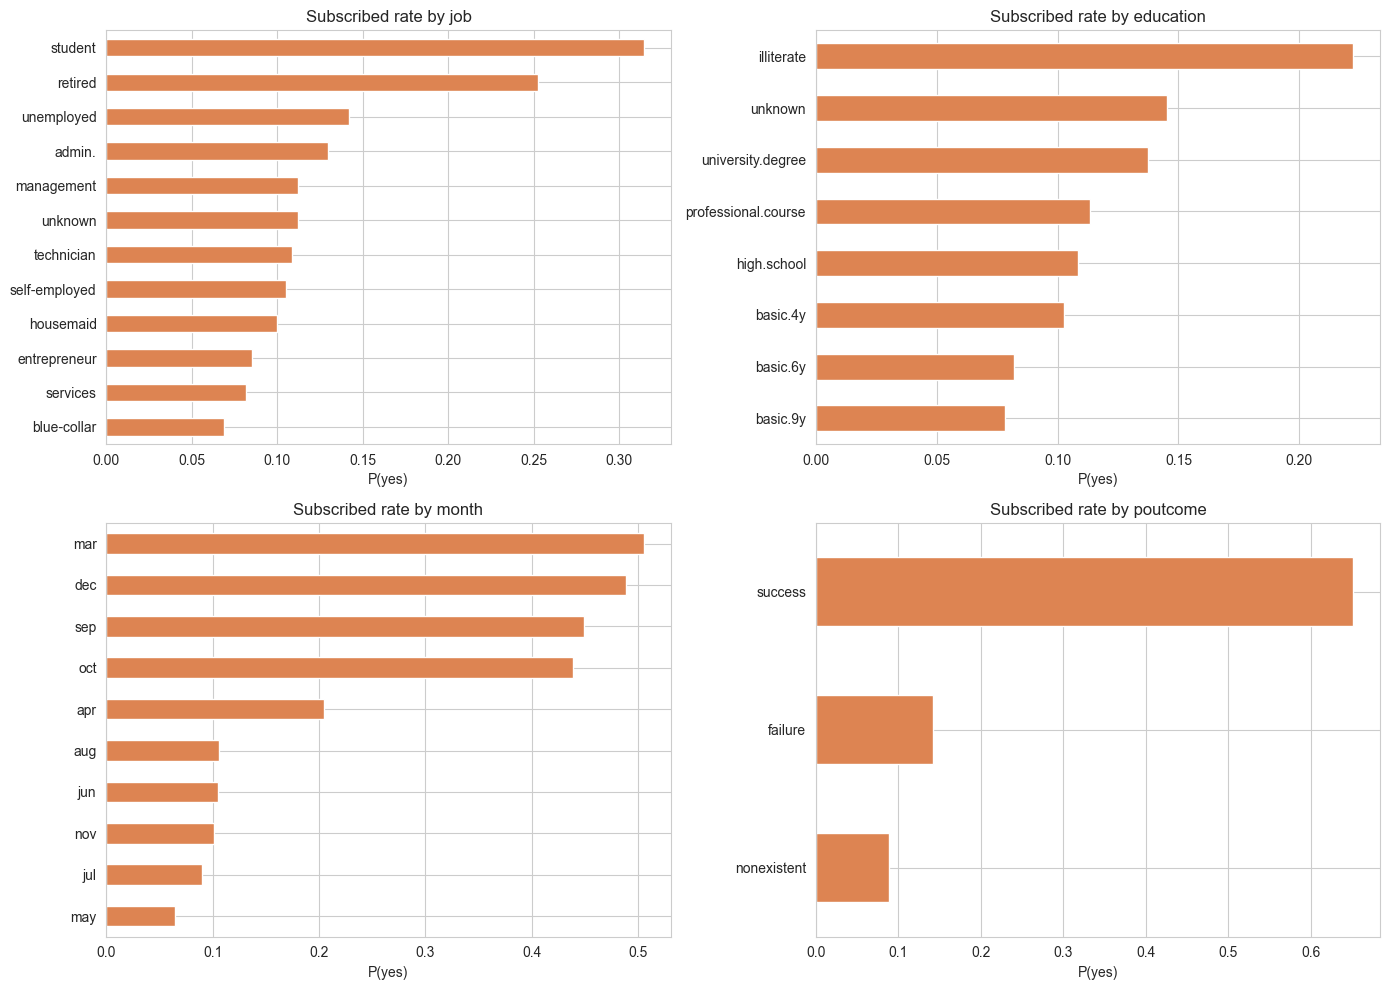

In [14]:
# How the target varies by key categoricals
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.ravel(), ["job", "education", "month", "poutcome"]):
    ct = pd.crosstab(df_clean[col], df_clean["y"], normalize="index")["yes"].sort_values()
    ct.plot(kind="barh", ax=ax, color="#DD8452")
    ax.set_title(f"Subscribed rate by {col}")
    ax.set_xlabel("P(yes)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Categorical exploration reveals strong predictive signals. poutcome is the most powerful feature: clients with a success outcome in a previous campaign subscribe at a rate of ~65%, compared to ~9% for failure or ~14% for nonexistent. job also varies significantly (students ~31%, retirees ~25% vs. blue-collar ~7%). education shows a general trend where higher education levels correspond to higher subscription rates, though the illiterate category must be interpreted cautiously due to a very small sample size (visualised rate is high, but absolute numbers are tiny). Finally, month shows extreme variation (March ~50% vs. May ~6%). Because month is a time-based variable, its high importance likely reflects specific campaign strategies or macroeconomic conditions during those months rather than a fundamental property of the client, time and macro-economic variables will therefore be treated cautiously.**

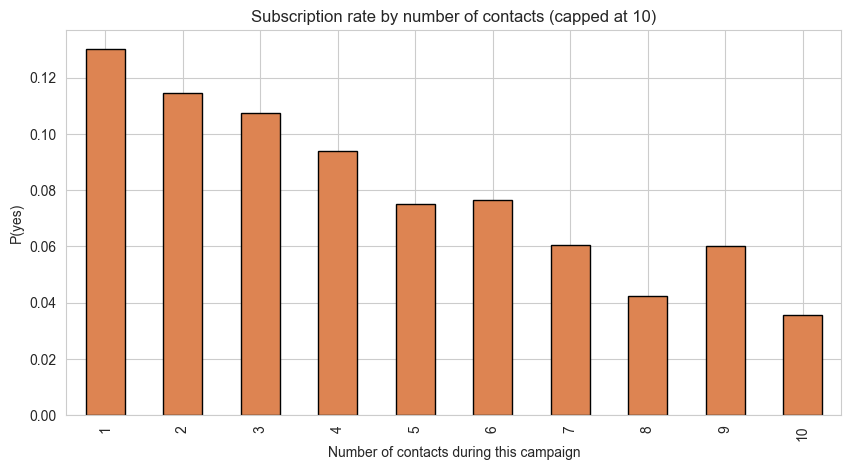

In [15]:
# Subscription rate by campaign
df_clean["campaign_capped"] = df_clean["campaign"].clip(upper=10)

# Plot
ct = pd.crosstab(df_clean["campaign_capped"], df_clean["y"], normalize="index")["yes"]
ct.plot(kind="bar", color="#DD8452", edgecolor="black")
plt.title("Subscription rate by number of contacts (capped at 10)")
plt.xlabel("Number of contacts during this campaign")
plt.ylabel("P(yes)")
plt.show()

**Insight on campaign: Subscription rate drops as contact attempts increase (13% at 1 call vs. 3.5% at 10+). This possibly reflects that clients who say 'no' are repeatedly contacted. Therefore, a high campaign count is a proxy for prior failed attempts, not a cause of failure.**

### Understanding the Leakage Risk (Duration)

In [16]:
# Mean duration by target
print(df_clean.groupby("y")["duration"].describe()[["mean", "50%", "min", "max"]])

           mean    50%   min     max
y                                   
no   220.868079  164.0   0.0  4918.0
yes  553.256090  449.0  37.0  4199.0


**duration (last contact duration, in seconds) is the strongest single predictor of y, with mean duration of ~550s for subscribers vs ~220s for non-subscribers. However, the model is designed to predict subscription before the first contact of a campaign. Therefore, duration (known only after a call) and campaign (the number of contacts during the current campaign) are excluded to prevent target leakage and timing bias. Historical variables (pdays, previous, poutcome) and macroeconomic indicators will be retained noting that the latter represent broader temporal trends rather than individual client traits.**

### Handling pdays = 999

In [17]:
# Counting rows with 999
print("pdays == 999:", (df_clean["pdays"] == 999).sum(), "rows")
print("Otherwise pdays range:", df_clean.loc[df_clean["pdays"] != 999, "pdays"].min(), "-",
      df_clean.loc[df_clean["pdays"] != 999, "pdays"].max())

pdays == 999: 39661 rows
Otherwise pdays range: 0 - 27


In [18]:
# Replacing the 999 placeholder with NaN because it does not represent an actual number of days
df_clean["pdays"] = df_clean["pdays"].replace(999, np.nan)

# Creating a binary indicator showing whether a client was previously contacted
# .notna() means the value is a real number (not NaN), so 1 = Previously contacted; 0 = Never previously contacted
df_clean["previously_contacted"] = df_clean["pdays"].notna().astype(int)

# Checking the distribution of previous contact status
print("Value counts for previously_contacted:")
print(df_clean["previously_contacted"].value_counts())

# Summarising the number of days since the previous contact (excluding clients never contacted)
print("\npdays describe:")
print(df_clean["pdays"].describe())

Value counts for previously_contacted:
previously_contacted
0    39661
1     1515
Name: count, dtype: int64

pdays describe:
count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays, dtype: float64


### Dropping Leaky Variables (Duration & Campaign)

In [19]:
# Droppin duration (known after call) and campaign (known during campaign)
df_clean = df_clean.drop(columns=["duration", "campaign"])
print("Remaining columns:", df_clean.shape[1])

Remaining columns: 21


**The model is designed to predict subscription before the first contact of a campaign. Therefore, duration (known only after a call) and campaign (number of contacts during the current campaign) are excluded to prevent target leakage and timing bias. Historical variables (pdays, previous, poutcome) and macroeconomic indicators are retained, noting that the latter represent broader temporal trends**

In [20]:
# Removing the temporary plotting column so it never enters the model
if "campaign_capped" in df_clean.columns:
    df_clean = df_clean.drop(columns=["campaign_capped"])
    
print("Final shape of df_clean:", df_clean.shape)

Final shape of df_clean: (41176, 20)


### Final Clean Checkpoint

In [21]:
import os
os.makedirs("data", exist_ok=True)
df_clean.to_csv("bank_cleaned.csv", index=False)
print("Saved cleaned data! Shape:", df_clean.shape)

Saved cleaned data! Shape: (41176, 20)


### Dataset Structure and Data Quality

The dataset contains 41,188 observations and 21 columns, comprising 20 predictor variables and one binary target variable (`y`), which indicates whether a client subscribed to a term deposit (`yes` or `no`). 

The predictor variables are divided into four categories:
1. **Client Demographics:** Age, job, marital status, education, credit default status, housing loan, and personal loan.
2. **Current Campaign Data:** Contact method, month, day of week, and call duration.
3. **Previous Campaign Data:** Number of contacts, days since last contact (`pdays`), previous contacts, and previous outcome (`poutcome`).
4. **Macroeconomic Context:** Employment variation rate, consumer price index, consumer confidence index, EURIBOR 3-month rate, and number of employees.

**Missing Values and Data Types:**
There are no explicit `NaN` or null values in the dataset. However, missingness is encoded as the string `'unknown'` in six categorical variables (e.g., `job`, `education`, `default`). `'unknown'` was retained as its own category to preserve the dataset size. All other variables are numeric (`int64` or `float64`), with categorical variables stored as strings (`object`).

**Data Quality and Leakage:**
Three major data quality issues were addressed:
1. **Duplicates:** A check identified **12 duplicate rows** (resulting in 24 identical records). These were removed to prevent over-weighting.
2. **Sentinel Values:** The `pdays` variable used `999` to indicate a client had never been previously contacted. This was replaced with `NaN`, and a new binary flag (`previously_contacted`) was created.
3. **Target Leakage:** The `duration` variable (length of the last call) was excluded because it is only known *after* the call, which contradicts the objective of predicting subscription *before* contacting the client. 

The dataset is highly imbalanced (~88.7% 'no', ~11.3% 'yes'), meaning accuracy is a misleading metric. The modelling process will rely on PR-AUC and F1-Score, using a stratified train-test split.

## TASK 2: Select and rank at-most 3 approaches and/or suitable for predicting the term-deposit subscription. Justify your selection and ranking with supporting evidence.

### Data Splitting, Preprocessing Pipeline, and Majority-Class Baseline

In [22]:
# Importing libraries for data splitting, preprocessing, baseline modelling and evaluation
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score


print("--- SPLITTING ---")

# 1. Encoding the target variable into binary format
# Converting "yes" (subscribed) to 1 and "no" (not subscribed) to 0
df_model = df_clean.copy()
df_model["y"] = (df_model["y"] == "yes").astype(int)

# Separating the target variable from the predictor features
y = df_model["y"]
X = df_model.drop(columns=["y"])

# Splitting the data into 80% training and 20% testing sets
# Stratification preserves the original target class proportions in both sets
# random_state ensures the same split can be reproduced
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


print("--- PREPROCESSING ---")

# 2. Identifying numerical and categorical predictor columns
num_features = X.select_dtypes(include=['number']).columns.tolist()
cat_features = X.select_dtypes(include=['object']).columns.tolist()

# Building a preprocessing pipeline for each feature type
# Numerical features: replacing missing values with the median, then standardise
# Categorical features: one-hot encoding categories into binary columns
# handle_unknown="ignore" prevents errors when test data contains unseen categories
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num_features),

    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)
])

# Fitting preprocessing steps on training data only to prevent data leakage
# Applying the learned transformations to both training and testing data
X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre = preprocessor.transform(X_test)


print("--- MAJORITY BASELINE ---")

# 3. Establishing a simple baseline using the majority target class
# The classifier always predicts the most frequent class in the training data
baseline = DummyClassifier(strategy="most_frequent", random_state=42)

# Training the baseline classifier and generating predictions on the test set
baseline.fit(X_train_pre, y_train)
y_pred_base = baseline.predict(X_test_pre)

# Obtaining predicted probabilities for the positive class (subscription = 1)
y_proba_base = baseline.predict_proba(X_test_pre)[:, 1]

# Evaluating baseline performance on the unseen test data
print(f"Accuracy : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_base, zero_division=0):.4f}")
print(f"PR-AUC   : {average_precision_score(y_test, y_proba_base):.4f}")

# Displaying the number of features created after preprocessing
print(f"Transformed Feature Count: {X_train_pre.shape[1]}")

--- SPLITTING ---
--- PREPROCESSING ---
--- MAJORITY BASELINE ---
Accuracy : 0.8873
F1 Score : 0.0000
PR-AUC   : 0.1127
Transformed Feature Count: 62


**Baseline Evaluation:
A majority-class baseline was established to contextualize model performance. The dummy classifier achieves an accuracy of 88.73% by predicting 'no' for every client, but scores 0.00 on F1 and a PR-AUC of 0.1127 (equal to the class prior). This confirms the 'accuracy trap' in imbalanced data: accuracy is a highly misleading metric. All subsequent models will be evaluated primarily on PR-AUC and F1, and must substantially beat this baseline floor.**

### Model Selection and Cross-Validation

**Baseline Models**

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd
import numpy as np

print("--- STEP 15: MODEL CROSS-VALIDATION ---")

# Defining the models being compared
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(), 
                             random_state=42, n_jobs=-1, eval_metric="logloss")
}

# Setting up 5-Fold Cross Validation (splits training data into 5 chunks to test robustness)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Metrics to evaluate
scoring = ["accuracy", "f1", "roc_auc", "average_precision"]

results = []

for name, model in models.items():
    print(f"Training {name}...")
    cv_results = cross_validate(model, X_train_pre, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    
    results.append({
        "Model": name,
        "Accuracy": cv_results["test_accuracy"].mean(),
        "F1 Score": cv_results["test_f1"].mean(),
        "ROC-AUC": cv_results["test_roc_auc"].mean(),
        "PR-AUC": cv_results["test_average_precision"].mean()
    })

# Showing results
results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df)

--- STEP 15: MODEL CROSS-VALIDATION ---
Training Logistic Regression...
Training Random Forest...
Training XGBoost...


,Accuracy,F1 Score,ROC-AUC,PR-AUC
Model,,,,
Logistic Regression,0.8298,0.4508,0.7894,0.4444
Random Forest,0.8851,0.3603,0.7662,0.3744
XGBoost,0.8367,0.4415,0.7671,0.4182


### Hyperparameter Tuning Models

**Tuning Logistic Regression**

In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, average_precision_score

print("Tuning Logistic Regression...")
lr_param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'solver': ['liblinear', 'lbfgs']
}

# 1. Running the Grid Search
lr_base = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_grid = GridSearchCV(lr_base, lr_param_grid, scoring='average_precision', cv=3, n_jobs=-1)
lr_grid.fit(X_train_pre, y_train)

print("\nBest LR Parameters:", lr_grid.best_params_)
print(f"Best CV PR-AUC: {lr_grid.best_score_:.4f}")

# 2. Evaluating on the Test Set
best_lr = lr_grid.best_estimator_
y_pred_lr_tuned = best_lr.predict(X_test_pre)
y_proba_lr_tuned = best_lr.predict_proba(X_test_pre)[:, 1]

print("\n--- Tuned Logistic Regression (Test Set) ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr_tuned):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_lr_tuned, zero_division=0):.4f}")
print(f"Test PR-AUC: {average_precision_score(y_test, y_proba_lr_tuned):.4f}")

Tuning Logistic Regression...

Best LR Parameters: {'C': 10.0, 'solver': 'lbfgs'}
Best CV PR-AUC: 0.4465

--- Tuned Logistic Regression (Test Set) ---
Accuracy : 0.8307
F1 Score : 0.4622
Test PR-AUC: 0.4435


**Tuning Random Forest**

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, average_precision_score

print("Tuning Random Forest...")
rf_param_grid = {
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 5, 10],
    'n_estimators': [100, 200]
}
rf_base = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)
rf_grid = GridSearchCV(rf_base, rf_param_grid, scoring='average_precision', cv=3, n_jobs=-1)
rf_grid.fit(X_train_pre, y_train)

print("Best RF Parameters:", rf_grid.best_params_)
print(f"Best CV PR-AUC: {rf_grid.best_score_:.4f}")

# Evaluating on test set
best_rf = rf_grid.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test_pre)
y_proba_rf_tuned = best_rf.predict_proba(X_test_pre)[:, 1]
print(f"Test PR-AUC: {average_precision_score(y_test, y_proba_rf_tuned):.4f}")

Tuning Random Forest...
Best RF Parameters: {'max_depth': 10, 'min_samples_leaf': 10, 'n_estimators': 100}
Best CV PR-AUC: 0.4606
Test PR-AUC: 0.4784


**Tuning XGBoost**

In [26]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, average_precision_score

print("Tuning XGBoost...")
xgb_param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200],
    'subsample': [0.8, 1.0]
}
xgb_base = XGBClassifier(scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(), 
                         random_state=42, eval_metric="logloss", n_jobs=-1)
xgb_grid = GridSearchCV(xgb_base, xgb_param_grid, scoring='average_precision', cv=3, n_jobs=-1)
xgb_grid.fit(X_train_pre, y_train)

print("Best XGB Parameters:", xgb_grid.best_params_)
print(f"Best CV PR-AUC: {xgb_grid.best_score_:.4f}")

# Evaluating on test set
best_xgb = xgb_grid.best_estimator_
y_pred_xgb_tuned = best_xgb.predict(X_test_pre)
y_proba_xgb_tuned = best_xgb.predict_proba(X_test_pre)[:, 1]
print(f"Test PR-AUC: {average_precision_score(y_test, y_proba_xgb_tuned):.4f}")

Tuning XGBoost...
Best XGB Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best CV PR-AUC: 0.4644
Test PR-AUC: 0.4766


**All Tuned Models Results**

In [27]:
from sklearn.metrics import accuracy_score, f1_score, average_precision_score
import pandas as pd

print("--- FINAL EVALUATION: ALL TUNED MODELS (TEST SET) ---")

# 1. Logistic Regression 
best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_pre)
y_proba_lr = best_lr.predict_proba(X_test_pre)[:, 1]

# 2. Random Forest
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_pre)
y_proba_rf = best_rf.predict_proba(X_test_pre)[:, 1]

# 3. XGBoost
best_xgb = xgb_grid.best_estimator_
y_pred_xgb = best_xgb.predict(X_test_pre)
y_proba_xgb = best_xgb.predict_proba(X_test_pre)[:, 1]

# Creating a unified DataFrame for easy viewing
final_metrics = pd.DataFrame([
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "F1 Score": f1_score(y_test, y_pred_lr, zero_division=0),
        "Test PR-AUC": average_precision_score(y_test, y_proba_lr)
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "F1 Score": f1_score(y_test, y_pred_rf, zero_division=0),
        "Test PR-AUC": average_precision_score(y_test, y_proba_rf)
    },
    {
        "Model": "Tuned XGBoost",
        "Accuracy": accuracy_score(y_test, y_pred_xgb),
        "F1 Score": f1_score(y_test, y_pred_xgb, zero_division=0),
        "Test PR-AUC": average_precision_score(y_test, y_proba_xgb)
    }
]).set_index("Model").round(4)

display(final_metrics)

--- FINAL EVALUATION: ALL TUNED MODELS (TEST SET) ---


,Accuracy,F1 Score,Test PR-AUC
Model,,,
Tuned Logistic Regression,0.8307,0.4622,0.4435
Tuned Random Forest,0.8567,0.5013,0.4784
Tuned XGBoost,0.8441,0.4852,0.4766


### Model Selection: Default vs. Tuned Performance

Three distinct algorithms were selected for comparison: Logistic Regression (linear), Random Forest (bagging), and XGBoost (boosting). Initially, all three were evaluated using their default settings. However, default configurations often struggle with imbalanced data and noise. Therefore, Grid Search with Cross-Validation was used to tune the hyperparameters of all three models, optimizing specifically for PR-AUC.

**Performance Comparison (Test Set):**

| Model | Default PR-AUC | Tuned PR-AUC | Final F1 Score |
| :--- | :--- | :--- | :--- |
| **Random Forest** | 0.3744 | **0.4784** | **0.5013** |
| **XGBoost** | 0.4182 | 0.4766 | 0.4852 |
| **Logistic Regression** | 0.4444 | 0.4435 | 0.4622 |

**Ranking and Justification:**

**1. Tuned Random Forest (Top Choice)**
This model achieved the highest final PR-AUC (0.4784) and F1 Score (0.5013). Notice the massive improvement from its default settings (PR-AUC 0.3744). The default Random Forest overfitted the noise, yielding high accuracy but failing to find actual subscribers. Tuning `max_depth` and `min_samples_leaf` forced the model to generalize, making it the most reliable tool for this campaign.

**2. Tuned XGBoost**
XGBoost was an extremely close second with a PR-AUC of 0.4766. Tuning boosted its default PR-AUC from 0.4182. While highly capable, it narrowly missed the top spot, suggesting Random Forest's bagging approach handled this specific dataset's noise slightly better.

**3. Tuned Logistic Regression**
Logistic Regression performed remarkably well with default settings (0.4444), and tuning did not significantly improve it (0.4435). Because the leaky variables (`duration` and `campaign`) were removed, the remaining data has a strong linear component. This model remains highly valuable because it performs competitively and is easily interpretable by business stakeholders.

## TASK 3: Recommend a decision threshold and explain the trade-off between unnecessary calls and missed subscribers

### The Decision Threshold

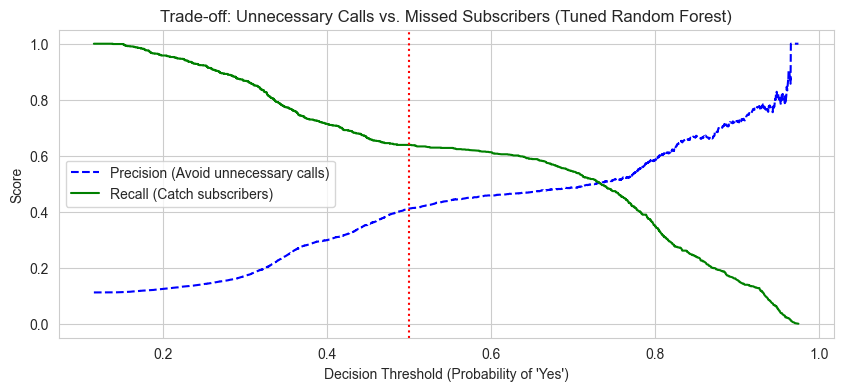

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Calculating precision, recall, and thresholds for the winning model
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_rf)

# Plotting
plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision (Avoid unnecessary calls)")
plt.plot(thresholds, recalls[:-1], "g-", label="Recall (Catch subscribers)")
plt.xlabel("Decision Threshold (Probability of 'Yes')")
plt.ylabel("Score")
plt.title("Trade-off: Unnecessary Calls vs. Missed Subscribers (Tuned Random Forest)")
plt.legend(loc="best")
plt.grid(True)
plt.axvline(x=0.5, color='red', linestyle=':', label='Default Threshold (0.5)')
plt.show()

In [29]:
# Comparing precision and recall at selected decision thresholds
selected_thresholds = [0.30, 0.40, 0.50]

for threshold in selected_thresholds:
    y_pred = (y_proba_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print("-" * 30)

Threshold: 0.3
Precision: 0.1719
Recall:    0.8675
------------------------------
Threshold: 0.4
Precision: 0.2995
Recall:    0.7134
------------------------------
Threshold: 0.5
Precision: 0.4124
Recall:    0.6390
------------------------------


### Decision Threshold Recommendation

The default decision threshold for classification is 0.50. However, in a marketing context, this threshold may not be optimal because the costs of false positives and false negatives differ.

Two types of classification errors are particularly relevant:

1. **False Positives (Unnecessary Calls):** Calling a client who does not subscribe, resulting in wasted agent time and resources.
2. **False Negatives (Missed Subscribers):** Failing to identify a client who would have subscribed if contacted, resulting in a missed business opportunity.

The results show that lowering the decision threshold increases recall while reducing precision. At the default threshold of 0.50, the Tuned Random Forest achieves a recall of 63.90%, meaning it identifies approximately 64% of actual subscribers. At a threshold of 0.30, recall increases to 86.75%, reducing the proportion of missed subscribers from 36.10% to 13.25%.

However, this improvement comes at the cost of lower precision, which falls from 41.24% at 0.50 to 17.19% at 0.30. This means that a larger proportion of clients contacted following the model's predictions would not subscribe.

**Recommendation:** A threshold of 0.30 is considered where the bank prioritises identifying as many potential subscribers as possible, accepting the additional calling costs associated with lower precision. A threshold of 0.40 offers a more balanced alternative, achieving 71.34% recall and 29.95% precision. The final threshold should depend on the bank's calling capacity and the relative costs of missed subscribers and unnecessary calls.